# 01 · The problem: weekly retail demand, and how results are judged

**The question.** How sparse is weekly item-store demand in M5, how is the forecast set up, and how is each result judged?
Notebooks 02 to 06 test which NeuralForecast training settings make a deep model fit this data. This one fixes the ground rules
they all share.

Notebooks 03 to 05 put four claims that practitioners often make to the test:

1. A handful of training settings decide whether deep learning works on retail demand (notebook 03).
2. Getting those settings wrong mostly makes the model underfit (notebook 03).
3. Gradient clipping is non-negotiable for likelihood losses such as Tweedie (notebook 04).
4. With the right settings, deep learning can match gradient-boosted trees (notebook 05).

Notebook 06 collects the verdicts.

Reading order: 01 the problem · 02 the recipe · 03 one setting at a time · 04 gradient clipping · 05 deep learning vs LightGBM ·
06 summary.

In [1]:
import sys, os
try: import m5knobs  # noqa: F401  (installed with pip install -e .)
except ImportError: sys.path.insert(0, os.path.abspath(".."))  # run from notebooks/
from m5knobs import data, paths, results, scoring
from IPython.display import Markdown, display
results.check_available()  # stops with instructions if results/ is missing

## The data

M5 is Walmart's public daily unit sales per item and store across three US states. Here it is summed to calendar weeks ending
Saturday, one series per item-store pair. Each series starts at its first week with a sale, so the zeros counted below are weeks
with no sales after the item first sold.

In [2]:
import pandas as pd, matplotlib.pyplot as plt
HAVE_DATA = os.path.exists(paths.M5_WEEKLY)
if HAVE_DATA:
    panel = data.load_panel()
    weeks, zero_share = panel.groupby("unique_id").size(), panel["y"].eq(0).groupby(panel["unique_id"]).mean()
else:
    print("data/m5_weekly.parquet not found: run `python3 scripts/prepare_data.py` to see the panel statistics.")

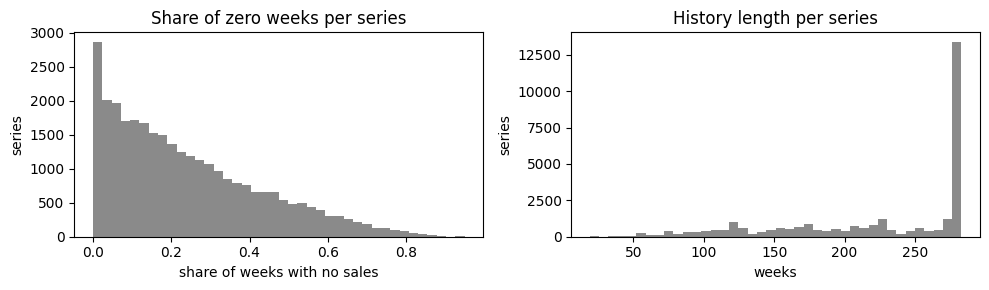

In [3]:
if HAVE_DATA:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].hist(zero_share, bins=40, color="#8a8a8a")
    ax[0].set(title="Share of zero weeks per series", xlabel="share of weeks with no sales", ylabel="series")
    ax[1].hist(weeks, bins=40, color="#8a8a8a")
    ax[1].set(title="History length per series", xlabel="weeks", ylabel="series")
    plt.tight_layout(); plt.show()

In [4]:
if HAVE_DATA:
    zs, w = zero_share, weeks
    display(Markdown(
        f"{len(w):,} series, {panel.ds.min():%Y-%m-%d} to {panel.ds.max():%Y-%m-%d}, {len(panel):,} series-weeks. "
        f"{panel.y.eq(0).mean():.0%} of all series-weeks sold nothing. Per series, the median share of zero weeks is "
        f"{zs.median():.0%}; a quarter of series have more than {zs.quantile(0.75):.0%} zero weeks, "
        f"and {zs.gt(0.5).mean():.0%} have more than half. History length runs from {w.quantile(0.1):.0f} weeks "
        f"(10th percentile) to {w.quantile(0.9):.0f} weeks (90th); {w.lt(52).mean():.0%} have less than a year."))

30,490 series, 2011-01-29 to 2016-06-25, 6,848,887 series-weeks. 24% of all series-weeks sold nothing. Per series, the median share of zero weeks is 19%; a quarter of series have more than 36% zero weeks, and 12% have more than half. History length runs from 117 weeks (10th percentile) to 283 weeks (90th); 1% have less than a year.

## The forecast setup

Every model forecasts a fixed number of weeks ahead from several origins (rolling origin). At each origin the model sees only
history up to that date. The setting cards in notebook 03 fit once at the first origin and forecast the later origins from newer
history with the same weights; the architecture comparison in notebook 05 refits at every origin. The data ends partway through
the last calendar week: the final weekly bucket holds one day of sales, so it is excluded from scoring (the rule: a final week
that totals under half the median of the four weeks before it is treated as partial). The last origin therefore scores
one week fewer than the others (counted below).

In [5]:
act = results.actuals()
cutoffs = data.CUTOFFS if HAVE_DATA else sorted(act["cutoff"].unique())
origins = ", ".join(f"{pd.Timestamp(c):%Y-%m-%d}" for c in cutoffs)
display(Markdown(f"Horizon `h={data.H}` weeks, `freq='{data.FREQ}'`, {len(cutoffs)} origins: {origins}. "
                 f"Scored weeks: {act.ds.min():%Y-%m-%d} to {act.ds.max():%Y-%m-%d}, "
                 f"{act.unique_id.nunique():,} series, {act.y.sum():,.0f} units in total. Scored weeks per origin: "
                 + ", ".join(str(n) for n in act.groupby("cutoff")["ds"].nunique()) + "."))

Horizon `h=13` weeks, `freq='W-SAT'`, 3 origins: 2015-09-26, 2015-12-26, 2016-03-26. Scored weeks: 2015-10-03 to 2016-06-18, 30,490 series, 10,796,897 units in total. Scored weeks per origin: 13, 13, 12.

In [6]:
if HAVE_DATA:
    tot = panel.groupby("ds")["y"].sum()
    display(Markdown(f"The final week ({tot.index[-1]:%Y-%m-%d}) totals {tot.iloc[-1]:,.0f} units, "
                     f"{tot.iloc[-1] / tot.iloc[-5:-1].median():.0%} of the median of the four weeks before it."))

The final week (2016-06-25) totals 47,065 units, 15% of the median of the four weeks before it.

Three example series appear in every setting card. They are picked by rule, not by eye: the **steady seller** is the series
nearest the median 52-week volume among series with under 20% zero weeks; the **intermittent** one is the same among series with
50 to 80% zero weeks; the **seasonal** one is a dense series in the top tenth of lag-52 autocorrelation, nearest the median volume.
Dotted lines mark the forecast origins.

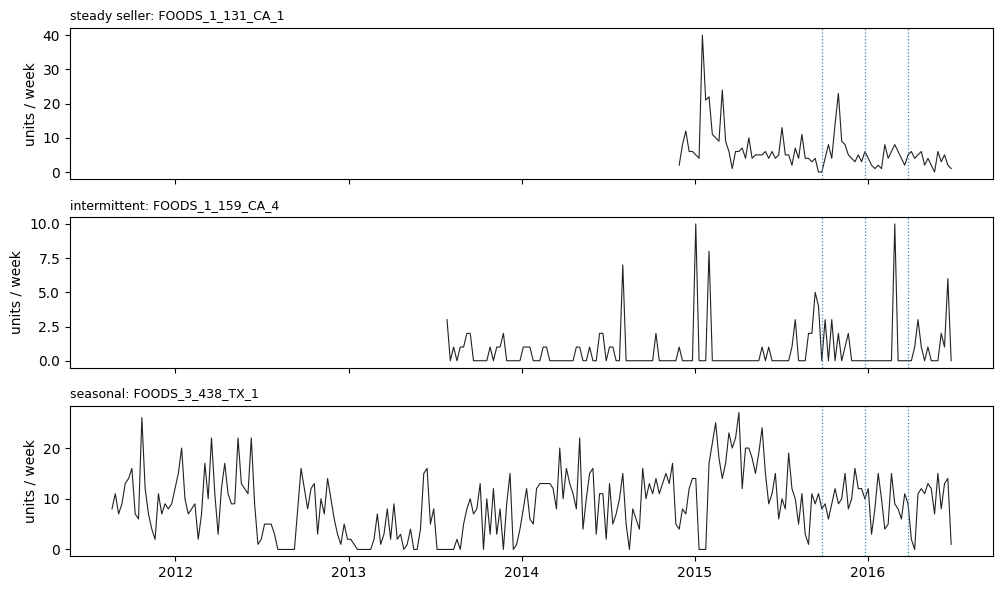

In [7]:
hist, names, ex = results.example_history(), ["steady seller", "intermittent", "seasonal"], results.examples3()
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for ax, uid, name in zip(axes, ex, names):
    s = hist[hist.unique_id == uid]
    ax.plot(s.ds, s.y, color="#222222", lw=0.8)
    ax.set_title(f"{name}: {uid}", loc="left", fontsize=9); ax.set_ylabel("units / week")
    [ax.axvline(c, color="#2e86ab", ls=":", lw=0.9) for c in cutoffs]
plt.tight_layout(); plt.show()

In [8]:
c0 = pd.Timestamp(cutoffs[0])
last = hist[(hist.ds <= c0) & (hist.ds > c0 - pd.Timedelta(weeks=52))].groupby("unique_id")["y"]
display(Markdown("In the 52 weeks before the first origin: " + "; ".join(
    f"{n} ({u}): {last.get_group(u).eq(0).mean():.0%} zero weeks, {last.get_group(u).sum():,.0f} units"
    for n, u in zip(names, ex)) + "."))

In the 52 weeks before the first origin: steady seller (FOODS_1_131_CA_1): 5% zero weeks, 335 units; intermittent (FOODS_1_159_CA_4): 77% zero weeks, 40 units; seasonal (FOODS_3_438_TX_1): 6% zero weeks, 664 units.

## How results are judged

- **WAPE**: total absolute error over all series, weeks and origins, divided by total actual units, in percent. Lower is better.
  Big sellers weigh more than slow ones.
- **Bias**: total forecast divided by total actual, minus one, in percent. Negative means the model under-forecast total volume.

Every run uses one seed. The seed-noise bar comes from the author's earlier 3-seed runs of the same model family on M5. Those runs are not part of this repo, so treat the bar as approximate.

To turn a pair of runs (a "without" run with one setting wrong, a "with" run at the recipe) into a verdict, four per-series
measures are compared: in-sample error on the training history, week-to-week correlation between forecast and actuals, how much
the forecast moves relative to the actuals (amplitude), and absolute total bias. A measure counts as hurt when it is worse in the
"without" run and a paired bootstrap over series gives p below the threshold. Then:

- **underfit**: fit, tracking or amplitude hurt, *and* the WAPE gap exceeds the seed-noise bar;
- **biased**: absolute bias hurt *and* worse by more than the bias noise bar;
- **both**: the underfit and the biased conditions are both met;
- **no clear effect on M5**: neither is met.

The rule only looks for harm from the wrong value. It has no verdict for the wrong value doing better; when that happens
the card's "what moved" text reports the gap in words and numbers.

In [9]:
noise = data.SEED_NOISE
display(Markdown(f"Seed-noise bar: ±{noise['wape']} WAPE points and ±{noise['bias']:.0f} bias points."))
display(pd.Series({"bootstrap p-value below": scoring.ALPHA, "underfit: WAPE gap above (points)": noise["wape"],
                   "biased: |bias| gap above (points)": noise["bias"]}, name="threshold").to_frame())

Seed-noise bar: ±0.2 WAPE points and ±1 bias points.

,threshold
bootstrap p-value below,0.05
underfit: WAPE gap above (points),0.20
biased: |bias| gap above (points),1.00


The rule applied to four made-up cases (which measures were hurt, the WAPE gap, the absolute-bias gap):

In [10]:
none = dict(insample_mae=False, corr=False, amp_ratio=False, abs_bias=False)
cases = {"tracking hurt, WAPE +0.5": (dict(none, corr=True), 0.5, 0.0),
         "tracking hurt, WAPE +0.1": (dict(none, corr=True), 0.1, 0.0),
         "|bias| hurt, +3pt": (dict(none, abs_bias=True), 0.0, 3.0),
         "fit and |bias| hurt, WAPE +0.6, +2pt": (dict(none, insample_mae=True, abs_bias=True), 0.6, 2.0)}
display(pd.Series({k: scoring.label_row(*v) for k, v in cases.items()}, name="verdict").to_frame())

,verdict
"tracking hurt, WAPE +0.5",underfit
"tracking hurt, WAPE +0.1",no clear effect on M5
"|bias| hurt, +3pt",biased
"fit and |bias| hurt, WAPE +0.6, +2pt",both


Two rules were set after seeing results, and are disclosed wherever they are used:

1. **The effect floor** (the WAPE and bias gaps above). With tens of thousands of series the bootstrap alone can flag differences
   far inside seed noise.
2. **The stress test's divergence rule** (notebook 04): a run diverged when its validation loss ended above twice its best, that is,
   it did not recover. The stressors themselves were fixed before any run.

## What to set

In [11]:
display(Markdown(f"""- Weekly data: `freq='{data.FREQ}'` in `NeuralForecast(...)`, `h={data.H}` on the model.
- Start each series at its first sale (`data.drop_leading_zeros`), so leading zeros don't count as demand.
- Score with WAPE *and* total bias, over several origins.
- Treat gaps under ±{data.SEED_NOISE['wape']} WAPE as ties unless you ran several seeds."""))

- Weekly data: `freq='W-SAT'` in `NeuralForecast(...)`, `h=13` on the model.
- Start each series at its first sale (`data.drop_leading_zeros`), so leading zeros don't count as demand.
- Score with WAPE *and* total bias, over several origins.
- Treat gaps under ±0.2 WAPE as ties unless you ran several seeds.

Next: [02 · The recipe](02_the_recipe.ipynb), every training setting and the code that sets it.